In [2]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import joblib

print("All libraries imported successfully!")



All libraries imported successfully!


In [3]:

housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:

print("Dataset shape:", df.shape)


Dataset shape: (20640, 9)


In [5]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:

df.describe()



,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:

print("Missing values:")
print(df.isnull().sum())


Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [8]:


duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)


Number of duplicate records: 0


In [9]:



df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


Dataset shape after removing duplicates: (20640, 9)


In [10]:


missing_values = df.isnull().sum()

print(missing_values)


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [12]:
df["AveRooms"] = df["AveRooms"].fillna(
    df["AveRooms"].median()
)

In [13]:

print("Final dataset information")

print("Rows and columns:", df.shape)

print("Total missing values:", df.isnull().sum().sum())

print("Total duplicates:", df.duplicated().sum())


Final dataset information
Rows and columns: (20640, 9)
Total missing values: 0
Total duplicates: 0


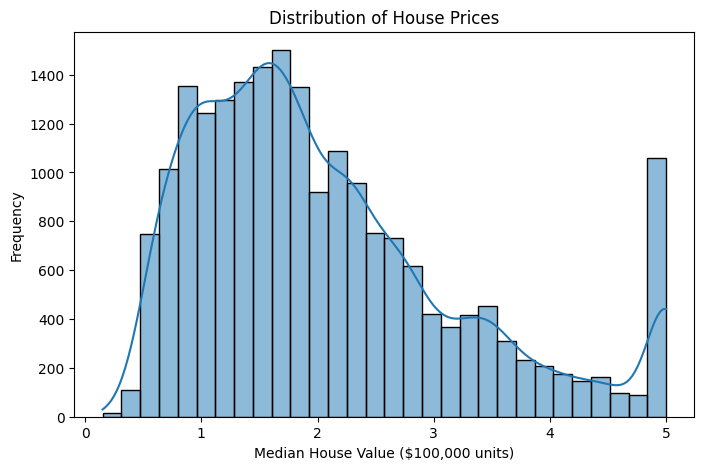

In [14]:



plt.figure(figsize=(8, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=30,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")

plt.show()


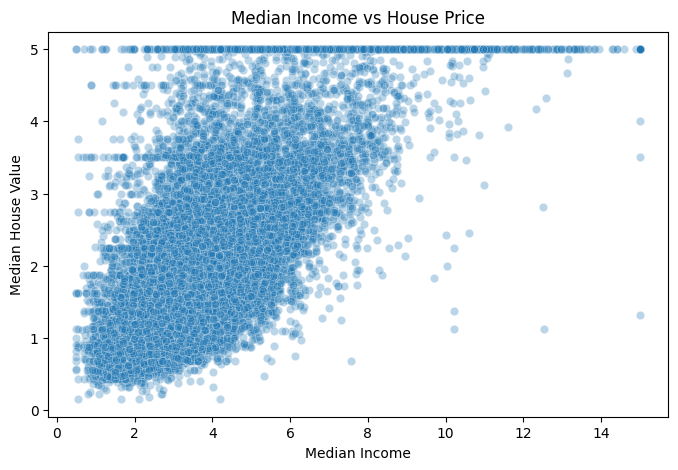

In [15]:




plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["MedInc"],
    y=df["MedHouseVal"],
    alpha=0.3
)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()


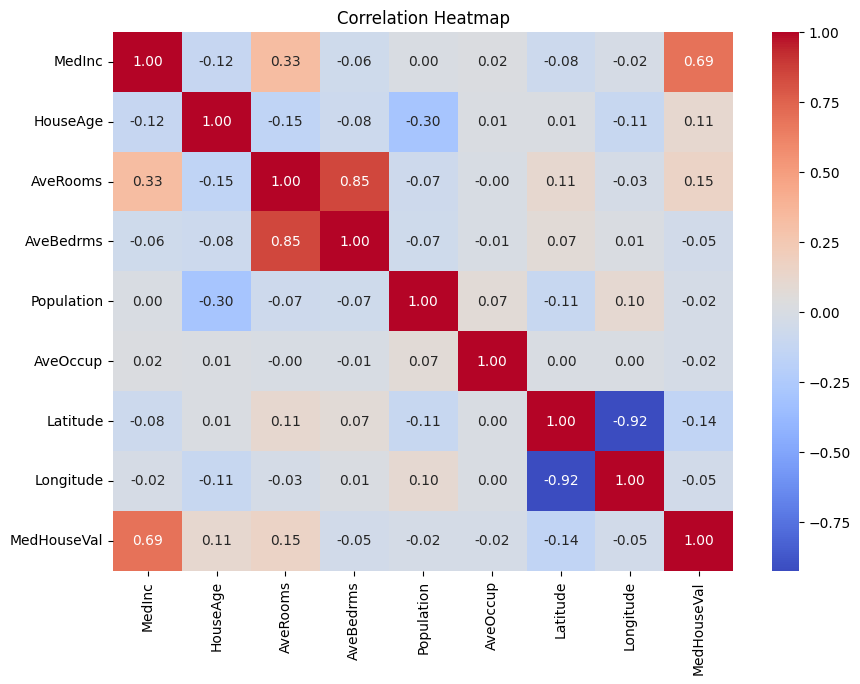

In [16]:


correlation = df.corr()



plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


In [17]:



X = df[
    [
        "MedInc",
        "HouseAge",
        "AveRooms",
        "AveBedrms",
        "Population",
        "AveOccup",
        "Latitude",
        "Longitude"
    ]
]



X.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [18]:



y = df["MedHouseVal"]



y.head()


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


In [19]:

print("Features shape:", X.shape)

print("Target shape:", y.shape)


Features shape: (20640, 8)
Target shape: (20640,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [21]:
model = LinearRegression()

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [22]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [23]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [24]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 0.745581383012776


In [25]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.5757877060324512


In [26]:
print("MODEL EVALUATION")
print("-------------------------")
print("RMSE:", round(rmse, 4))
print("RMSE in dollars:", round(rmse * 100000, 2))
print("R² Score:", round(r2, 4))


MODEL EVALUATION
-------------------------
RMSE: 0.7456
RMSE in dollars: 74558.14
R² Score: 0.5758


In [27]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients)


      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


In [28]:
print("Model Intercept:", model.intercept_)

Model Intercept: -37.02327770606405


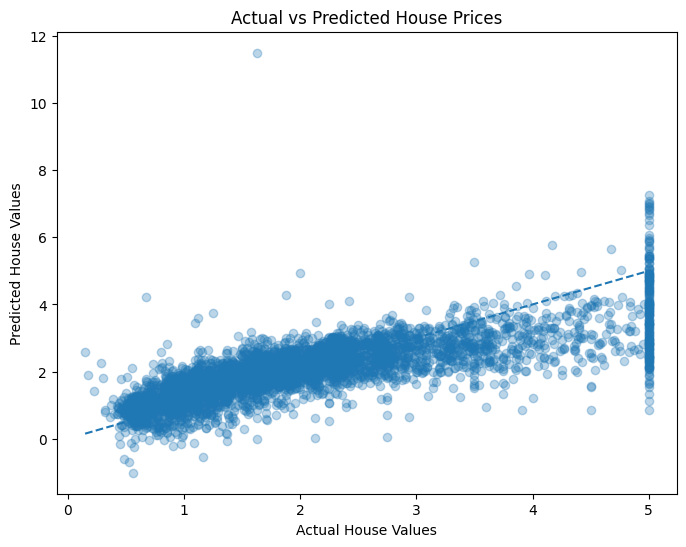

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Prices")


plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [30]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [31]:
loaded_model = joblib.load("house_price_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [32]:
loaded_predictions = loaded_model.predict(X_test)

print("First 10 predictions:")
print(loaded_predictions[:10])

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [33]:
new_house = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [20.0],
    "AveRooms": [6.0],
    "AveBedrms": [1.2],
    "Population": [1000.0],
    "AveOccup": [3.0],
    "Latitude": [34.05],
    "Longitude": [-118.25]
})

print(new_house)


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0     5.0      20.0       6.0        1.2      1000.0       3.0     34.05   

   Longitude  
0    -118.25  


In [34]:
predicted_value = loaded_model.predict(new_house)

print("Predicted value:", predicted_value[0])

Predicted value: 2.5938517614227123


In [35]:
price_in_dollars = predicted_value[0] * 100000

print("Predicted house value: ${:,.2f}".format(price_in_dollars))

Predicted house value: $259,385.18
